# Orbit Wars — Environment Tutorial

Bu notebook `kaggle_environments` üstündeki **Orbit Wars** ortamını adım adım keşfetmek için yazıldı. Sonunda:

1. Ortamın iç yapısını (`interpreter`, `state`, `observation`) anlayacaksın.
2. Bir oyunu baştan sona oynatabileceksin (`env.run`).
3. **Manuel step-by-step** kontrol kuracaksın (RL eğitiminin temeli).
4. `env.train()` ile **Gym tarzı** wrapper kullanacaksın.
5. Observation ve action space'i görselleştireceksin.
6. RL pipeline'ına nasıl bağlanacağını göreceksin.

> **Önkoşul**: `pip install kaggle-environments matplotlib` ve `orbit_wars` ortamının kurulu olması.

## 1. Setup & Imports

İlk olarak gerekli paketleri import edelim. `kaggle_environments` import edilirken bazı opsiyonel ortamlarla ilgili uyarılar görebilirsin (`cabt`, `open_spiel` vb.) — bunlar Orbit Wars'ı etkilemez, görmezden gelebilirsin.

In [62]:
import math
import json
import random
import warnings
from pprint import pprint

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrow

from kaggle_environments import make
from kaggle_environments.envs.orbit_wars.orbit_wars import (
    Planet, Fleet, CENTER, ROTATION_RADIUS_LIMIT,
    random_agent, starter_agent,
)

warnings.filterwarnings("ignore")
random.seed(0); np.random.seed(0)
print("Imports OK")

Imports OK


## 2. Environment'ı Oluştur ve Yapısını İncele

`make("orbit_wars")` bize bir `Environment` nesnesi döner. Bu nesnenin önemli alanları:

| Alan | Açıklama |
|---|---|
| `env.specification` | JSON spec (observation, action, configuration şeması) |
| `env.configuration` | Aktif config (episodeSteps, shipSpeed, vs.) |
| `env.state` | Tüm ajanların state listesi (her ajan için `observation`, `action`, `reward`, `status`) |
| `env.steps` | Şu ana kadar oynanan tüm step'lerin listesi (replay) |
| `env.done` | Oyun bitti mi? |
| `env.run(agents)` | Tüm episode'u oynat |
| `env.reset(num_agents)` | Sıfırla |
| `env.step(actions)` | Tek bir adım ilerlet (manuel kontrol) |
| `env.train(agents)` | Gym-style single-agent wrapper döner |
| `env.render(mode=...)` | Görselleştir |

In [63]:
env = make("orbit_wars", debug=True)

print("Spec name :", env.specification.name if hasattr(env.specification, "name") else env.name)
print("Agents    :", env.specification.agents)        # [2, 4] -> 2 veya 4 oyuncu
print("Episode   :", env.configuration.episodeSteps, "turn")
print("ActTimeout:", env.configuration.actTimeout, "saniye/turn")
print("ShipSpeed :", env.configuration.shipSpeed)
print("Done?     :", env.done)
env

Spec name : orbit_wars
Agents    : [2, 4]
Episode   : 500 turn
ActTimeout: 1 saniye/turn
ShipSpeed : 6.0
Done?     : False


In [64]:
env.configuration

{'episodeSteps': 500,
 'actTimeout': 1,
 'runTimeout': 1200,
 'agentTimeout': 2,
 'shipSpeed': 6.0,
 'cometSpeed': 4.0}

### `interpreter` ve `observe` fonksiyonları nerede?

Orbit Wars motorunun kalbi şu dosyada:

```
kaggle_environments/envs/orbit_wars/orbit_wars.py
```

Önemli fonksiyonlar:

- **`interpreter(state, env)`** — Gym'deki `step()` karşılığı. Tüm ajanların action'larını alır, fleet launch / production / movement / combat'ı uygular, her `state[i].observation`'ı günceller.
- **`renderer(state, env)`** — text rendering.
- **`html_renderer(env, mode)`** — interaktif HTML görselleştirme.
- **`random_agent`, `starter_agent`** — hazır rakipler.

`kaggle_environments` Gym'deki gibi ayrı bir `observe()` fonksiyonu kullanmaz; observation `interpreter` içinde state'e yazılır. Aşağıdaki hücre fonksiyonun yerini gösterir.

### `Environment` ve `state` — Detaylı Anatomi

`kaggle_environments`'ta tek bir merkezi sınıf var: **`Environment`** (kaynak: `kaggle_environments/core.py:159`). Klasik Gym'deki gibi ayrı bir `State` sınıfı **yok** — state bir **list of dicts** (her ajan için bir dict). Bu dict'ler `Struct` adlı yardımcı bir sarmalla `obj.field` notasyonuyla erişilebilir hale gelir, ama altında düz dict.

#### `Environment` sınıfının önemli alanları

| Alan | Tip | Açıklama |
|---|---|---|
| `specification` | Struct | JSON spec (observation/action/configuration şeması, `agents=[2,4]` vb.) |
| `configuration` | Struct | Aktif config (`episodeSteps`, `actTimeout`, `shipSpeed`, `cometSpeed`...) |
| `interpreter` | Callable | Step mantığını uygulayan fonksiyon (`orbit_wars.interpreter`) |
| `renderer` | Callable | Text render |
| `html_renderer` | Callable | İnteraktif HTML render |
| `agents` | dict[str, Callable] | "random", "starter_agent" gibi hazır rakipler |
| `state` | list[Struct] | **Mevcut** state — her ajan için bir entry |
| `steps` | list[list[Struct]] | Geçmiş tüm step'lerin listesi (replay) |
| `logs` | list[list[dict]] | Her step'te ajanların stdout/timing/exception bilgisi |
| `done` | bool (property) | Tüm ajanlar `INACTIVE`/`DONE`/`ERROR` mı? |
| `info` | dict | Episode metadata |
| `id` | str | UUID |

#### `Environment`'ın önemli metotları

| Metot | Görevi |
|---|---|
| `reset(num_agents=None)` | Episode'u sıfırlar, ilk state'i döner |
| `step(actions)` | **Tüm ajanların** action listesini alır, `interpreter`'ı çağırır, yeni state döner |
| `run(agents)` | Episode'u sonuna kadar oynatır (her turda otomatik action sampling) |
| `train(agents)` | Bir slotu `None` bırakırsın, **Gym-style trainer** döner (`reset()` / `step(action)`) |
| `render(mode=...)` | `"ansi"`, `"human"`, `"ipython"`, `"html"`, `"json"` |
| `clone()` | Mevcut state'in kopyasını çıkarır (planning / MCTS için) |
| `toJSON()` | Tüm episode'u JSON olarak serialize eder |

#### `state` listesi — her ajan için bir dict

`env.state` veya `env.steps[t]` listesinin **her elemanı** bir ajan için durumu temsil eder ve şu alanları içerir:

| Anahtar | Tip | Açıklama |
|---|---|---|
| `action` | Any | O ajanın bu turda sunduğu hamle (Orbit Wars'ta `[[from, angle, ships], ...]`) |
| `reward` | float | Anlık reward (Orbit Wars'ta sadece episode sonunda anlamlı) |
| `info` | dict | Ajan-spesifik bilgi |
| `observation` | Struct | **Asıl gözlem** — ajanın o turda gördüğü dünya |
| `status` | str | `"ACTIVE"`, `"INACTIVE"`, `"DONE"`, `"ERROR"`, `"INVALID"`, `"TIMEOUT"` |

#### Orbit Wars'ta `observation` alanları

| Anahtar | Tip | Açıklama |
|---|---|---|
| `player` | int | Ajanın kendi ID'si (0–3) |
| `planets` | list[list] | `[id, owner, x, y, radius, ships, production]` — tüm gezegenler (cometler dahil) |
| `fleets` | list[list] | `[id, owner, x, y, angle, from_planet_id, ships]` |
| `initial_planets` | list[list] | Oyun başındaki konumlar (rotation prediction için) |
| `angular_velocity` | float | Orbital gezegenlerin dönüş hızı (rad/turn) |
| `comets` | list[dict] | Aktif kuyruklu yıldız grupları: `{planet_ids, paths, path_index}` |
| `comet_planet_ids` | list[int] | Hangi planet ID'leri aslında comet |
| `next_fleet_id` | int | Sonraki fleet'e atanacak ID |
| `remainingOverageTime` | float | Time budget (saniye) |
| `step` | int | Mevcut tur numarası |

> **Önemli:** `observation` her ajan için **ayrı** tutulur. Orbit Wars tam-bilgili (full-information) olduğu için içerik aynıdır, sadece `player` farklıdır. Kısmi bilgi gereken oyunlarda (Hanabi gibi) burada filtreleme yapılır.

Aşağıdaki hücre bunları canlı olarak inceler.

In [65]:
# Environment ve state'i canlı incele
env_demo = make("orbit_wars", debug=True)
state = env_demo.reset(num_agents=2)

print("=== Environment ===")
print("type           :", type(env_demo).__name__)
print("name / version :", env_demo.name, "/", env_demo.version)
print("done           :", env_demo.done)
print("step sayısı    :", len(env_demo.steps))
print("agents (hazır) :", list(env_demo.agents.keys()))
print("public attrs   :", [a for a in dir(env_demo) if not a.startswith("_")][:15], "...")

print("\n=== state (list of per-agent dicts) ===")
print("len(state)     :", len(state))
print("state[0] keys  :", list(state[0].keys()))
print("status / reward:", state[0].status, "/", state[0].reward)

print("\n=== state[0].observation ===")
obs = state[0].observation
print("obs keys       :", list(obs.keys()))
print("player         :", obs.player)
print("# planets      :", len(obs.planets))
print("# fleets       :", len(obs.fleets))
print("ang. velocity  :", round(obs.angular_velocity, 4))

=== Environment ===
type           : Environment
name / version : orbit_wars / 1.0.9
done           : False
step sayısı    : 1
agents (hazır) : ['random', 'starter']
public attrs   : ['agents', 'clone', 'configuration', 'debug', 'debug_print', 'done', 'html_renderer', 'id', 'info', 'interpreter', 'logs', 'name', 'play', 'pool', 'render'] ...

=== state (list of per-agent dicts) ===
len(state)     : 2
state[0] keys  : ['action', 'reward', 'info', 'observation', 'status']
status / reward: ACTIVE / 0

=== state[0].observation ===
obs keys       : ['remainingOverageTime', 'step', 'planets', 'fleets', 'player', 'angular_velocity', 'initial_planets', 'next_fleet_id', 'comets', 'comet_planet_ids']
player         : 0
# planets      : 0
# fleets       : 0
ang. velocity  : 0


In [66]:
env.state[0].keys()

dict_keys(['action', 'reward', 'info', 'observation', 'status'])

In [67]:
env.state[0].action, env.state[0].observation.keys()

([],
 dict_keys(['remainingOverageTime', 'step', 'planets', 'fleets', 'player', 'angular_velocity', 'initial_planets', 'next_fleet_id', 'comets', 'comet_planet_ids']))

In [68]:
env.configuration

{'episodeSteps': 500,
 'actTimeout': 1,
 'runTimeout': 1200,
 'agentTimeout': 2,
 'shipSpeed': 6.0,
 'cometSpeed': 4.0}

In [72]:
# env.steps: replay buffer — her step'te tüm ajanların durumu
print("Şu ana kadar oynanan step sayısı:", len(env_demo.steps))
print("env.steps[0] (ilk turn) ajan sayısı:", len(env_demo.steps[0]))
print("env.steps[0][0].status:", env_demo.steps[0][0].status)

# Bir adım at, steps'in nasıl büyüdüğünü gör
env_demo.step([[], []])
print("\n1 step sonrası:")
print("  len(env.steps) =", len(env_demo.steps))
print("  son step status:", env_demo.steps[-1][0].status)
print("  step alanı (interpreter güncelliyor):", env_demo.steps[-1][0].observation.step
      if hasattr(env_demo.steps[-1][0].observation, "step") else "—")

Şu ana kadar oynanan step sayısı: 3
env.steps[0] (ilk turn) ajan sayısı: 2
env.steps[0][0].status: ACTIVE

1 step sonrası:
  len(env.steps) = 4
  son step status: ACTIVE
  step alanı (interpreter güncelliyor): 3


In [73]:
import inspect
import kaggle_environments.envs.orbit_wars.orbit_wars as ow

print("Source file:", inspect.getsourcefile(ow))
print("interpreter at line:", inspect.getsourcelines(ow.interpreter)[1])
print("renderer    at line:", inspect.getsourcelines(ow.renderer)[1])
print("random_agent line  :", inspect.getsourcelines(ow.random_agent)[1])

# interpreter'ın imzasını ve docstring'ini gör
print("\nSignature:", inspect.signature(ow.interpreter))

Source file: /Users/doruksarigun/Kaggle/orbit-wars/orbit_wars_env/lib/python3.14/site-packages/kaggle_environments/envs/orbit_wars/orbit_wars.py
interpreter at line: 352
renderer    at line: 722
random_agent line  : 760

Signature: (state, env)


## 3. İlk Observation'ı Görelim

`env.reset(num_agents=2)` ortamı başlatır ve **ilk state**'i döner. Her ajan için bir `state` elemanı vardır; içinde `observation`, `action`, `reward`, `status`, `info` alanları bulunur.

In [74]:
state = env.reset(num_agents=2)

print(f"Toplam ajan sayısı: {len(state)}")
print(f"Her state elemanı şu alanları içerir: {list(state[0].keys())}\n")

obs0 = state[0].observation
print(f"Player ID         : {obs0.player}")
print(f"Planet sayısı     : {len(obs0.planets)}")
print(f"Fleet sayısı      : {len(obs0.fleets)}")
print(f"Angular velocity  : {obs0.angular_velocity:.4f} rad/turn")
print(f"Comet planet IDs  : {obs0.comet_planet_ids}")
print(f"\nİlk 3 gezegen (id, owner, x, y, radius, ships, production):")
for p in obs0.planets[:3]:
    print(" ", p)

Toplam ajan sayısı: 2
Her state elemanı şu alanları içerir: ['action', 'reward', 'info', 'observation', 'status']

Player ID         : 0
Planet sayısı     : 0
Fleet sayısı      : 0
Angular velocity  : 0.0000 rad/turn
Comet planet IDs  : []

İlk 3 gezegen (id, owner, x, y, radius, ships, production):


In [75]:
# Named tuple ile daha okunaklı erişim
planets = [Planet(*p) for p in obs0.planets]

print(f"{'id':>3} {'owner':>6} {'x':>7} {'y':>7} {'radius':>7} {'ships':>6} {'prod':>5}")
for p in planets:
    print(f"{p.id:>3} {p.owner:>6} {p.x:>7.2f} {p.y:>7.2f} {p.radius:>7.2f} {p.ships:>6} {p.production:>5}")

my_planets = [p for p in planets if p.owner == 0]
print(f"\nPlayer 0 home planet sayısı: {len(my_planets)}")

 id  owner       x       y  radius  ships  prod

Player 0 home planet sayısı: 0


## 4. Board'u Çiz

Her şeyi konumlandırmak için basit bir matplotlib görselleştirmesi yazalım.

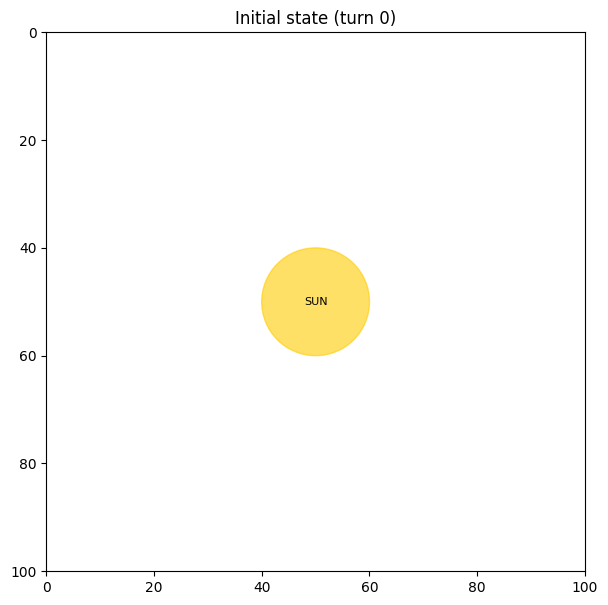

In [76]:
PLAYER_COLORS = {-1: "#888888", 0: "#1f77b4", 1: "#d62728", 2: "#2ca02c", 3: "#ff7f0e"}

def draw_board(obs, ax=None, title=""):
    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 7))
    ax.set_xlim(0, 100); ax.set_ylim(100, 0)  # y'yi ters çevir (origin top-left)
    ax.set_aspect("equal"); ax.set_title(title)

    # Sun
    ax.add_patch(Circle((50, 50), 10, color="#ffcc00", alpha=0.6))
    ax.text(50, 50, "SUN", ha="center", va="center", fontsize=8)

    comet_ids = set(obs.comet_planet_ids if hasattr(obs, "comet_planet_ids") else obs.get("comet_planet_ids", []))
    raw_planets = obs.planets if hasattr(obs, "planets") else obs["planets"]
    raw_fleets  = obs.fleets  if hasattr(obs, "fleets")  else obs["fleets"]

    for p in raw_planets:
        pl = Planet(*p)
        color = PLAYER_COLORS.get(pl.owner, "gray")
        edge = "white" if pl.id in comet_ids else "black"
        ax.add_patch(Circle((pl.x, pl.y), pl.radius, color=color, alpha=0.7, ec=edge, lw=1.5))
        ax.text(pl.x, pl.y, f"{pl.id}\n{pl.ships}", ha="center", va="center", fontsize=7, color="white")

    for f in raw_fleets:
        fl = Fleet(*f)
        color = PLAYER_COLORS.get(fl.owner, "gray")
        dx = math.cos(fl.angle) * 2
        dy = math.sin(fl.angle) * 2
        ax.add_patch(FancyArrow(fl.x, fl.y, dx, dy, color=color, width=0.4, length_includes_head=True))
        ax.text(fl.x + dx, fl.y + dy, str(fl.ships), fontsize=6, color=color)
    return ax

draw_board(obs0, title="Initial state (turn 0)");
plt.show()

## 5. Action Format

Her turda bir ajan **moves** listesi döndürür:

```python
[[from_planet_id, angle_in_radians, num_ships], ...]
```

- `from_planet_id` → senin sahip olduğun bir gezegen
- `angle_in_radians` → fleet'in yöneleceği yön (`atan2(dy, dx)`)
- `num_ships` → o gezegende mevcut ship'ten az veya eşit, integer

Aşağıda manuel bir hamle örneği üretelim: Player 0 home planet'inden Player 1'e doğru bir fleet gönderelim.

In [77]:
def example_move(obs, my_player):
    planets = [Planet(*p) for p in obs.planets]
    mine = next((p for p in planets if p.owner == my_player), None)
    enemy = next((p for p in planets if p.owner not in (-1, my_player)), None)
    if mine is None or enemy is None or mine.ships < 2:
        return []
    angle = math.atan2(enemy.y - mine.y, enemy.x - mine.x)
    ships = mine.ships // 2
    return [[mine.id, angle, ships]]

moves_p0 = example_move(obs0, 0)
print("Player 0 moves:", moves_p0)

Player 0 moves: []


## 6. Manuel Step-by-Step (`env.step`)

`env.step(actions)`:

- Argüman: **her ajan için bir action listesi** (yani `[moves_player_0, moves_player_1]`).
- Dönüş: yeni `state` (yine her ajan için bir entry).
- Her step'te `interpreter` çağrılır → fleet hareketi, çarpışma, üretim, savaş.

Bu, RL için kritik kontrol noktası — her turda ne olduğunu izleyebilirsin.

In [78]:
# Yeni bir env, manuel kontrol
env = make("orbit_wars", debug=True)
state = env.reset(num_agents=2)
obs0, obs1 = state[0].observation, state[1].observation

# Tek bir tur ilerlet: P0 yarısını gönderir, P1 hiçbir şey yapmaz
actions = [example_move(obs0, 0), []]
state = env.step(actions)

print("Turn :", env.steps[-1][0].observation.step if hasattr(env.steps[-1][0].observation, "step") else len(env.steps) - 1)
print("P0 status:", state[0].status, "reward:", state[0].reward)
print("P1 status:", state[1].status, "reward:", state[1].reward)
print("Aktif fleet sayısı:", len(state[0].observation.fleets))
print("İlk fleet:", state[0].observation.fleets[0] if state[0].observation.fleets else "yok")

Turn : 1
P0 status: ACTIVE reward: 0
P1 status: ACTIVE reward: 0
Aktif fleet sayısı: 0
İlk fleet: yok


Step sayısı : 22
Done?       : False
Aktif fleet : 2
P0 gezegen  : 1
P1 gezegen  : 1
Neutral     : 34


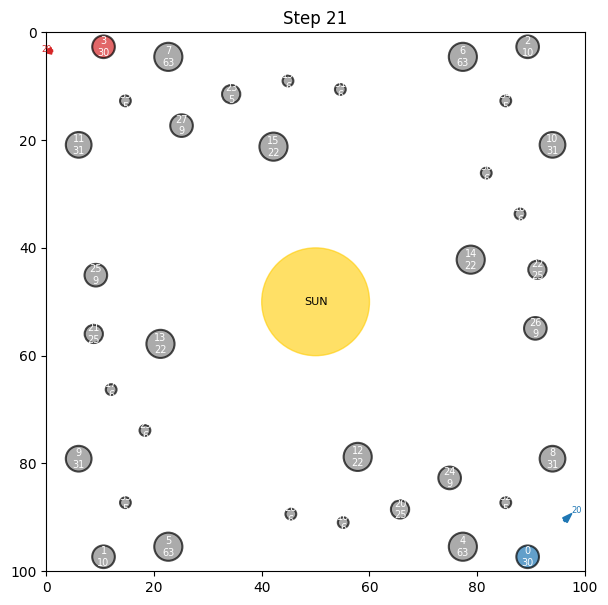

In [79]:
# 20 tur boyunca ileri gidelim, her ajan random hamle yapsın
for t in range(20):
    a0 = random_agent(state[0].observation)
    a1 = random_agent(state[1].observation)
    state = env.step([a0, a1])
    if env.done:
        break

obs0 = state[0].observation
print(f"Step sayısı : {len(env.steps)}")
print(f"Done?       : {env.done}")
print(f"Aktif fleet : {len(obs0.fleets)}")

# Sahiplik dağılımı
owners = [Planet(*p).owner for p in obs0.planets]
print(f"P0 gezegen  : {owners.count(0)}")
print(f"P1 gezegen  : {owners.count(1)}")
print(f"Neutral     : {owners.count(-1)}")

draw_board(obs0, title=f"Step {len(env.steps)-1}")
plt.show()

## 7. Tüm Episode'u Çalıştır (`env.run`)

Eğitimden ziyade **debugging / leaderboard simülasyonu** için pratik. Liste içinde fonksiyon, "random", "main.py" path'i veya `starter_agent` gibi callable verebilirsin.

In [ ]:
env_run = make("orbit_wars", debug=True)
final_state = env_run.run([starter_agent, random_agent])

print(f"Toplam step : {len(env_run.steps)}")
print(f"P0 reward   : {final_state[-1][0].reward}")
print(f"P1 reward   : {final_state[-1][1].reward}")
print(f"P0 status   : {final_state[-1][0].status}")
print(f"P1 status   : {final_state[-1][1].status}")

In [ ]:
# Replay'i incele: her adımdaki ship sayısı
def total_ships(obs, owner):
    s = sum(Planet(*p).ships for p in obs.planets if Planet(*p).owner == owner)
    s += sum(Fleet(*f).ships for f in obs.fleets if Fleet(*f).owner == owner)
    return s

p0_ships, p1_ships = [], []
for step in env_run.steps:
    obs = step[0].observation
    p0_ships.append(total_ships(obs, 0))
    p1_ships.append(total_ships(obs, 1))

plt.figure(figsize=(10, 4))
plt.plot(p0_ships, label="P0 (starter_agent)", color=PLAYER_COLORS[0])
plt.plot(p1_ships, label="P1 (random_agent)", color=PLAYER_COLORS[1])
plt.xlabel("Turn"); plt.ylabel("Total ships"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Ship count over the game")
plt.show()

In [ ]:
# Replay'i HTML olarak render et (notebook'ta interaktif animasyon)
from IPython.display import HTML
html = env_run.render(mode="html", width=700, height=600)
HTML(html)

## 8. Gym-Style Wrapper (`env.train`) — RL İçin Anahtar

`env.train(agents)` listesinde **`None`** koyduğun slot **senin RL ajanın**. Diğerleri ortam tarafından otomatik oynatılır.

Dönen `trainer` nesnesi klasik Gym API'sını sunar:
- `obs = trainer.reset()` → ilk observation (sadece senin slot'un)
- `obs, reward, done, info = trainer.step(action)` → bir tur ilerlet

Bu, PPO / DQN / SAC gibi standart RL kütüphaneleriyle entegrasyon noktasıdır.

In [ ]:
env_train = make("orbit_wars", debug=False)
trainer = env_train.train([None, "random"])  # slot 0 = bizim policy, slot 1 = random

obs = trainer.reset()
print("İlk observation tipi :", type(obs).__name__)
print("Anahtarlar           :", list(obs.keys()) if isinstance(obs, dict) else dir(obs)[:10])

# Basit policy: starter_agent fonksiyonunu kullanarak step'le
done = False
total_reward = 0.0
turn = 0
while not done:
    action = starter_agent(obs)
    obs, reward, done, info = trainer.step(action)
    total_reward += reward
    turn += 1
    if turn % 100 == 0:
        print(f"  turn={turn} reward_step={reward} done={done}")

print(f"\nEpisode bitti — toplam tur: {turn}, kümülatif reward: {total_reward}")

## 9. Observation → Tensor (RL için Encoding)

Observation değişken uzunluklu (gezegen sayısı 20–40, fleet sayısı dinamik). Neural net'e vermek için **sabit boyutlu padding + mask** kullanmak en basit yöntem.

Aşağıdaki encoder her gezegen için 8-feature'lık vektör üretir:

```
[is_mine, is_enemy, is_neutral, x/100, y/100, radius/10, ships/100, production/5]
```

In [ ]:
MAX_PLANETS = 60
MAX_FLEETS  = 200
PLANET_FEAT = 8
FLEET_FEAT  = 6

def encode_obs(obs, my_player):
    raw_p = obs.planets if hasattr(obs, "planets") else obs["planets"]
    raw_f = obs.fleets  if hasattr(obs, "fleets")  else obs["fleets"]

    planet_arr = np.zeros((MAX_PLANETS, PLANET_FEAT), dtype=np.float32)
    planet_mask = np.zeros(MAX_PLANETS, dtype=np.float32)
    for i, p in enumerate(raw_p[:MAX_PLANETS]):
        pl = Planet(*p)
        planet_arr[i] = [
            float(pl.owner == my_player),
            float(pl.owner not in (-1, my_player)),
            float(pl.owner == -1),
            pl.x / 100.0, pl.y / 100.0,
            pl.radius / 10.0,
            pl.ships / 100.0,
            pl.production / 5.0,
        ]
        planet_mask[i] = 1.0

    fleet_arr = np.zeros((MAX_FLEETS, FLEET_FEAT), dtype=np.float32)
    fleet_mask = np.zeros(MAX_FLEETS, dtype=np.float32)
    for i, f in enumerate(raw_f[:MAX_FLEETS]):
        fl = Fleet(*f)
        fleet_arr[i] = [
            float(fl.owner == my_player),
            fl.x / 100.0, fl.y / 100.0,
            math.cos(fl.angle), math.sin(fl.angle),
            fl.ships / 100.0,
        ]
        fleet_mask[i] = 1.0

    return {
        "planets": planet_arr, "planet_mask": planet_mask,
        "fleets":  fleet_arr,  "fleet_mask":  fleet_mask,
    }

enc = encode_obs(state[0].observation, my_player=0)
print({k: v.shape for k, v in enc.items()})
print("Aktif gezegen:", int(enc["planet_mask"].sum()), "| aktif fleet:", int(enc["fleet_mask"].sum()))

## 10. Action Decoding (Policy → Moves)

RL policy'nden çıkan action vektörünü oyunun beklediği `[[from, angle, ships], ...]` formatına çevirmek lazım.

**En basit şema (per-planet head):** Sahip olduğun her gezegen için bir karar üret:
- `target_planet_idx`: hangi gezegene saldıracaksın (discrete)
- `ship_fraction ∈ [0, 1]`: o gezegendeki ship'in ne kadarı gönderilecek

Angle, kaynak ve hedef gezegenlerden `atan2` ile otomatik hesaplanır.

In [ ]:
def decode_action(obs, my_player, target_idxs, ship_fracs):
    """
    target_idxs: dict {source_planet_id: target_planet_idx_in_obs.planets}
    ship_fracs : dict {source_planet_id: float in [0,1]}
    """
    planets = [Planet(*p) for p in (obs.planets if hasattr(obs, "planets") else obs["planets"])]
    moves = []
    for src in planets:
        if src.owner != my_player or src.id not in target_idxs:
            continue
        tgt_idx = target_idxs[src.id]
        if tgt_idx >= len(planets) or planets[tgt_idx].id == src.id:
            continue
        tgt = planets[tgt_idx]
        ships = int(src.ships * ship_fracs.get(src.id, 0.0))
        if ships <= 0:
            continue
        angle = math.atan2(tgt.y - src.y, tgt.x - src.x)
        moves.append([src.id, angle, ships])
    return moves

# Örnek: rastgele bir policy
def random_policy(obs, my_player=0):
    planets = [Planet(*p) for p in obs.planets]
    my_ids = [p.id for p in planets if p.owner == my_player]
    if not my_ids or len(planets) < 2:
        return []
    target_idxs = {sid: random.randrange(len(planets)) for sid in my_ids}
    ship_fracs  = {sid: random.uniform(0, 1)             for sid in my_ids}
    return decode_action(obs, my_player, target_idxs, ship_fracs)

print("Örnek policy çıktısı:", random_policy(state[0].observation, my_player=0)[:3])

## 11. Reward Shaping (Sparse → Dense)

Final reward sadece kazan/kaybet (sparse). Eğitimi hızlandırmak için **dense reward** üret:

```
r_t = α · Δ(my_total_ships) + β · Δ(my_planet_count) + γ · final_win_bonus
```

Aşağıdaki yardımcı fonksiyon her step için bunu hesaplar.

In [ ]:
class ShapedReward:
    def __init__(self, my_player=0, alpha=0.001, beta=0.05, gamma=1.0):
        self.p = my_player
        self.alpha, self.beta, self.gamma = alpha, beta, gamma
        self.prev_ships = None
        self.prev_planets = None

    def reset(self, obs):
        self.prev_ships = total_ships(obs, self.p)
        self.prev_planets = sum(1 for x in obs.planets if Planet(*x).owner == self.p)

    def step(self, obs, terminal_reward=0.0, done=False):
        cur_ships = total_ships(obs, self.p)
        cur_planets = sum(1 for x in obs.planets if Planet(*x).owner == self.p)
        d_s = cur_ships - self.prev_ships
        d_p = cur_planets - self.prev_planets
        self.prev_ships, self.prev_planets = cur_ships, cur_planets
        r = self.alpha * d_s + self.beta * d_p
        if done:
            r += self.gamma * terminal_reward
        return r

# Mini test
env_train = make("orbit_wars", debug=False)
trainer = env_train.train([None, "random"])
obs = trainer.reset()
shaper = ShapedReward(my_player=0)
shaper.reset(obs)

shaped_rewards = []
done = False
while not done:
    action = starter_agent(obs)
    obs, raw_r, done, _ = trainer.step(action)
    r = shaper.step(obs, terminal_reward=raw_r, done=done)
    shaped_rewards.append(r)

print(f"Toplam shaped reward: {sum(shaped_rewards):.3f}, episode tur sayısı: {len(shaped_rewards)}")
plt.plot(shaped_rewards); plt.title("Shaped reward / step"); plt.xlabel("turn"); plt.grid(alpha=0.3); plt.show()

## 12. Sıradaki Adımlar

1. **Bu notebook'tan çıkarılan parçalar** ile bir `env_wrapper.py` yaz: `encode_obs`, `decode_action`, `ShapedReward` → standart Gym `Env` sınıfına sar.
2. PyTorch / Stable-Baselines3 ile **PPO** eğit. Tip: `MultiInputPolicy` (dict obs için).
3. **Self-play**: bir slotu `None` (öğrenen), diğerini eski checkpoint olarak doldur. Belirli aralıklarla checkpoint havuzunu güncelle.
4. **Submission**: trained policy ağırlıklarını `main.py` ile aynı klasöre koy, `tar.gz` yapıp gönder:
   ```bash
   tar -czf submission.tar.gz main.py policy.pt
   kaggle competitions submit orbit-wars -f submission.tar.gz -m "PPO v1"
   ```

**Hatırlatma**: turn başına **1 saniye** süre limiti var → inference hızlı olmalı (CPU üzerinde). Ağır model kullanırsan distillation / quantization düşün.